# Fit a GAM with correlated Gaussian errors

Serially correlated errors affect fitting. The figures below compare fitted means and residual correlation. This example supplies a known AR(1) correlation of 0.7 and explicitly marks the starts of four independent series. It does not estimate a general correlation model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Simulate independent series with correlated errors

The Gaussian identity-link mean is shared across series. Correlation restarts at each marked boundary; no whitening step connects the last observation of one series with the first of the next.

In [2]:
rho=.7
frames=[]
for series in range(4):
    x=np.linspace(0,1,120)
    error=np.zeros(len(x))
    error[0]=rng.normal(0,.3/np.sqrt(1-rho*rho))
    for i in range(1,len(x)):error[i]=rho*error[i-1]+rng.normal(0,.3)
    frames.append(pd.DataFrame({"x":x,"y":np.sin(2*np.pi*x)+error,"series":series,"new_series":np.arange(len(x))==0}))
data=pd.concat(frames,ignore_index=True)

## Fit the independent-error model

Both fits use the same spline basis and REML criterion with BFGS smoothing optimization. The first treats the errors as independent.

In [3]:
from nampy.gam.diagnostics import build_optimizer_trace

ordinary = GAM(
    formula="y ~ s(x, bs='cr', k=12)",
    optimize_smoothing=True,
    smoothing_method="reml",
    smoothing_optimizer="bfgs",
).fit(data)
ordinary_convergence = build_optimizer_trace(ordinary)["fit"]
assert ordinary_convergence["converged"], ordinary_convergence["message"]
assert ordinary.fit_result().core.converged

## Fit the model with known AR(1) correlation

BFGS is used because the default Newton route failed its smoothing-convergence check for this correlated-error fit. It retains the same REML criterion and model terms. We inspect the smoothing result and the coefficient-fit convergence before comparing predictions.

In [4]:
correlated = GAM(
    formula="y ~ s(x, bs='cr', k=12)",
    ar1_rho=rho,
    ar_start="new_series",
    optimize_smoothing=True,
    smoothing_method="reml",
    smoothing_optimizer="bfgs",
).fit(data)
correlated_convergence = build_optimizer_trace(correlated)["fit"]
assert correlated_convergence["converged"], correlated_convergence["message"]
assert correlated.fit_result().core.converged

## Inspect the mean and residual correlation

We calculate lag correlations within each series and average them, excluding pairs across series boundaries. Standardized residuals use the same known-correlation transform as the fitted model.

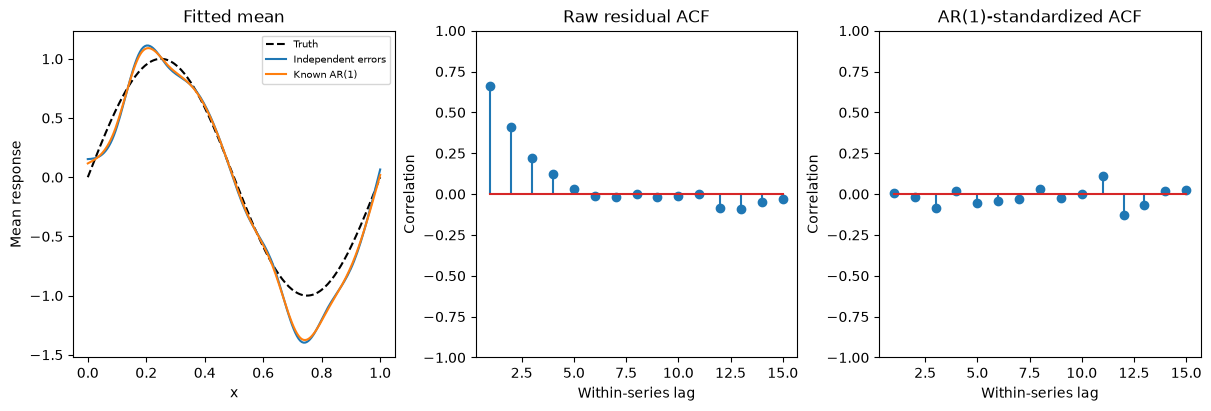

In [5]:
def within_series_acf(residual):
    chunks=np.asarray(residual).reshape(4,120)
    return np.array([np.mean([np.corrcoef(chunk[:-lag],chunk[lag:])[0,1] for chunk in chunks]) for lag in range(1,16)])
raw=correlated.residuals(type="response")
standardized=correlated.ar1_standardized_residuals()
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
figure,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
axes[0].plot(grid.x,np.sin(2*np.pi*grid.x),"k--",label="Truth")
axes[0].plot(grid.x,ordinary.predict(grid),label="Independent errors")
axes[0].plot(grid.x,correlated.predict(grid),label="Known AR(1)")
axes[0].set(xlabel="x",ylabel="Mean response",title="Fitted mean")
axes[0].legend(fontsize=7)
for axis,values,title in zip(axes[1:],[raw,standardized],["Raw residual ACF","AR(1)-standardized ACF"]):
    axis.stem(np.arange(1,16),within_series_acf(values))
    axis.set(xlabel="Within-series lag",ylabel="Correlation",title=title,ylim=(-1,1))
plt.show()
plt.close(figure)

The supplied correlation changes the fitted mean and the residual transformation. Read the standardized ACF within each independent series; it diagnoses what remains after applying the known AR(1) model, rather than estimating the correlation parameter.